# Results: *Learning to Trade via Direct Reinforcement* (Moody & Saffell, 2001)

This notebook **reads the saved results** in `results/`; it does not retrain anything (except the small gradient check in section 1).
To regenerate the results from scratch:

```bash
.venv/bin/python experiments/exp1_synthetic.py --seed 0
.venv/bin/python experiments/fetch_data.py      # once
.venv/bin/python experiments/exp2_sp500.py --seed 0
```

Assumptions and deviations from the paper are in `NOTES.md`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
RES = ROOT / "results"
import sys; sys.path.insert(0, str(ROOT))

from experiments.plot_style import INK_2, SERIES, plt
%matplotlib inline
pd.set_option("display.precision", 3)

## 1. Gradient check (Milestone 1)

The hand-derived batch gradient of the Sharpe ratio, including the recurrent term `dF_{t-1}/dθ`, compared with central finite differences on a short random problem. The full set of checks, including PyTorch autograd, is in `tests/test_gradients.py`.

In [2]:
from src.rrl import batch_gradient

rng = np.random.default_rng(0)
T, n = 60, 8
X, r = rng.normal(size=(T, n)), 0.01 * rng.normal(size=T)
theta = rng.normal(0, 0.5, size=n + 2)
kw = dict(t_start=0, t_end=T, delta=0.01)

U, grad, _ = batch_gradient(theta, X, r, **kw)
h, fd = 1e-6, np.zeros_like(theta)
for i in range(len(theta)):
    e = np.zeros_like(theta); e[i] = h
    fd[i] = (batch_gradient(theta + e, X, r, **kw)[0] - batch_gradient(theta - e, X, r, **kw)[0]) / (2 * h)

names = ["bias"] + [f"r(t-{k})" for k in range(n - 1, -1, -1)] + ["F(t-1)"]
pd.DataFrame({"hand-derived": grad, "finite diff": fd, "abs error": np.abs(grad - fd)}, index=names)

,hand-derived,finite diff,abs error
bias,0.006,0.006,2.874e-11
r(t-7),-0.437,-0.437,8.392e-11
r(t-6),0.033,0.033,1.765e-10
r(t-5),-0.411,-0.411,2.155e-10
r(t-4),0.298,0.298,1.024e-10
r(t-3),-0.145,-0.145,2.273e-10
r(t-2),-0.294,-0.294,1.133e-10
r(t-1),0.061,0.061,3.056e-10
r(t-0),-0.207,-0.207,1.514e-10
F(t-1),0.430,0.430,2.589e-10


## 2. Experiment 1: artificial price series (paper Sec. IV-A)

### Single trader learning on-line from scratch, cost 0.5% (paper Figs. 2 and 3)

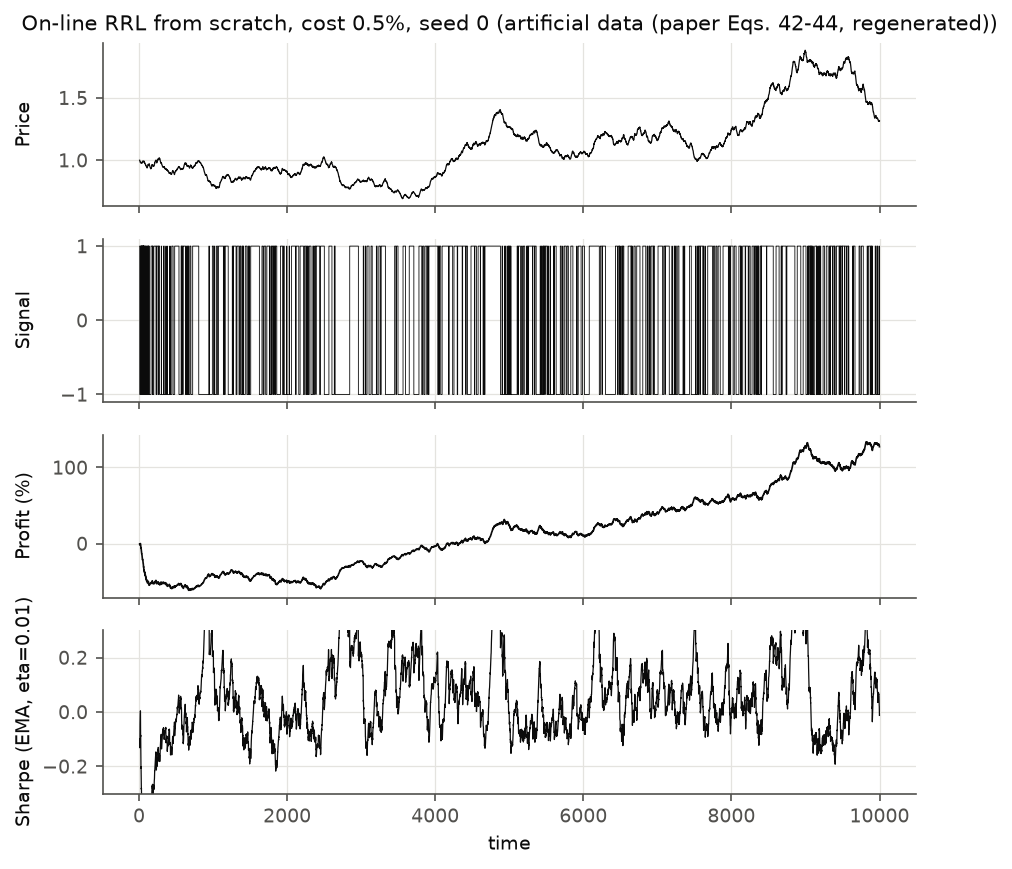

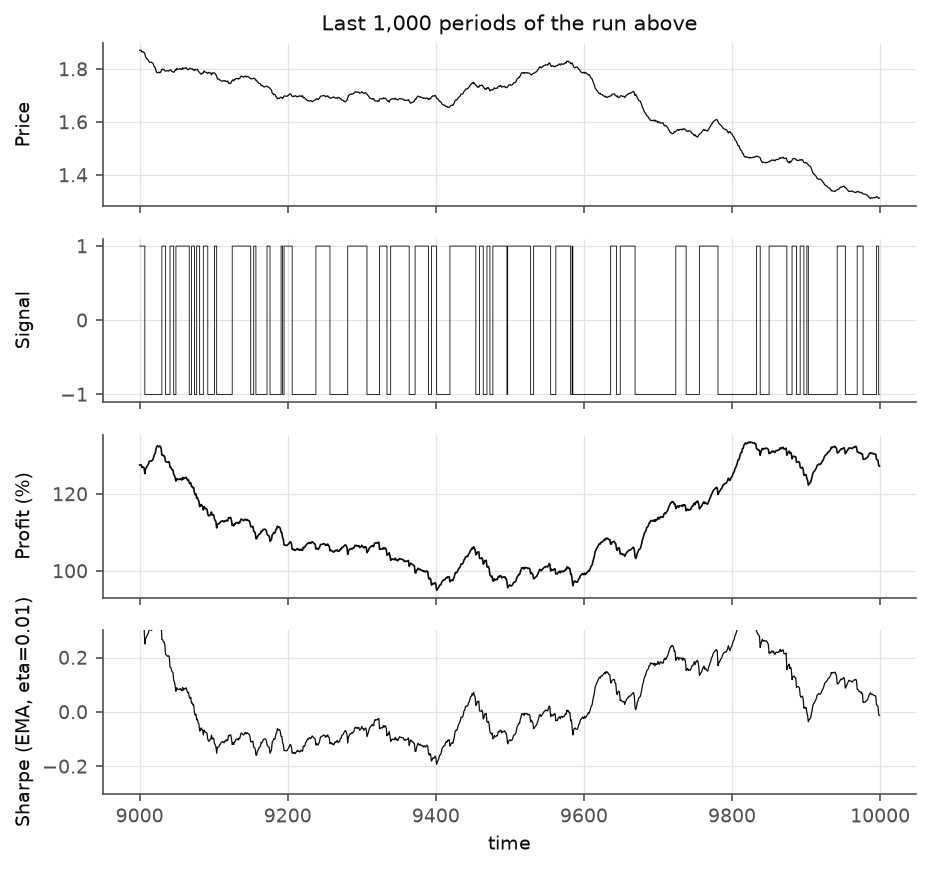

In [3]:
display(Image(RES / "exp1_fig2_single_run.png"))
display(Image(RES / "exp1_fig3_last1000.png"))

### 100 trials per cost level (paper Fig. 5)

Medians over 100 trials; the paper's values are approximate, read off its box plots.

In [4]:
s1 = json.loads((RES / "exp1_summary.json").read_text())
rows = []
for cost in ["0.2%", "0.5%", "1%"]:
    s, p = s1[cost], s1[cost]["paper_median"]
    rows.append({"cost": cost,
                 "trade freq % (ours)": s["median_trade_freq_pct"], "(paper)": p["trade_freq_pct"],
                 "profit % (ours)": s["median_profit_pct"], "(paper) ": p["profit_pct"],
                 "Sharpe (ours)": s["median_sharpe"], "(paper)  ": p["sharpe"],
                 "Sharpe > 0 (ours)": f'{100 * s["frac_positive_sharpe"]:.0f}%', "(paper)   ": "100%"})
print("config:", s1["config"])
pd.DataFrame(rows).set_index("cost")

config: {'seed': 0, 'trials': 100, 'rho': 0.001, 'rho_single_run': 0.01, 'eta': 0.01, 'init_scale': 0.1, 'warmup': 100, 'epochs': 100}


,trade freq % (ours),(paper),profit % (ours),(paper),Sharpe (ours),(paper),Sharpe > 0 (ours),(paper)
cost,,,,,,,,
0.2%,7.19,6.0,549.8,590,0.184,0.213,100%,100%
0.5%,4.64,4.2,339.6,430,0.091,0.137,98%,100%
1%,3.19,3.1,113.8,225,0.025,0.059,70%,100%


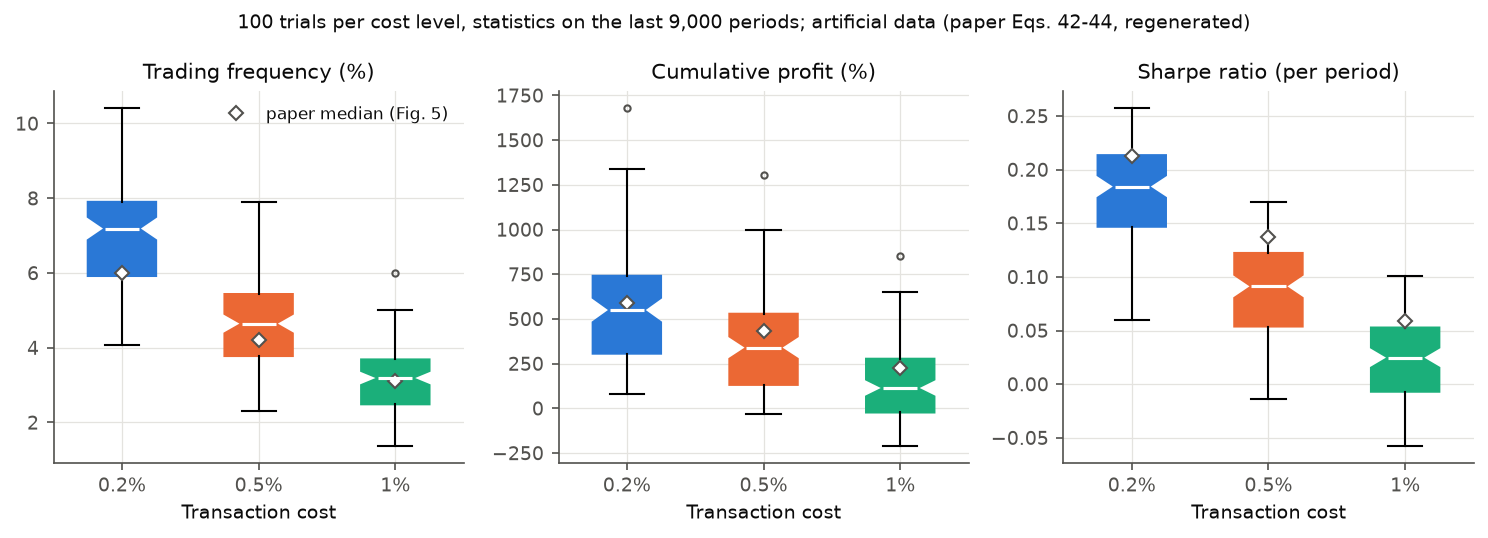

In [5]:
display(Image(RES / "exp1_fig5_boxplots.png"))

Full per-trial distribution (the same 100 price series are used at each cost level, so trials are paired by seed):

In [6]:
trials = pd.read_csv(RES / "exp1_trials.csv")
trials["cost"] = (100 * trials.delta).map("{:g}%".format)
trials.groupby("cost")[["sharpe", "profit_pct", "trade_freq_pct"]].describe(percentiles=[.1, .25, .5, .75, .9]).T

cost                      0.2%      0.5%       1%
sharpe         count   100.000   100.000  100.000
               mean      0.178     0.088    0.022
               std       0.044     0.044    0.038
               min       0.060    -0.014   -0.057
               10%       0.115     0.029   -0.031
               25%       0.147     0.054   -0.007
               50%       0.184     0.091    0.025
               75%       0.213     0.122    0.053
               90%       0.227     0.141    0.067
               max       0.257     0.170    0.101
profit_pct     count   100.000   100.000  100.000
               mean    563.019   358.218  137.689
               std     305.343   252.558  203.660
               min      78.605   -29.141 -208.980
               10%     192.803    63.829  -91.984
               25%     305.787   131.239  -23.154
               50%     549.759   339.593  113.764
               75%     741.272   528.841  277.317
               90%     966.034   683.745  386.216
               max    1678.803  1307.506  853.969
trade_freq_pct count   100.000   100.000  100.000
               mean      7.017     4.552    3.125
               std       1.429     1.182    0.870
               min       4.078     2.300    1.378
               10%       5.008     2.864    1.944
               25%       5.919     3.778    2.486
               50%       7.189     4.644    3.189
               75%       7.903     5.436    3.686
               90%       8.924     6.077    4.090
               max      10.411     7.900    6.011

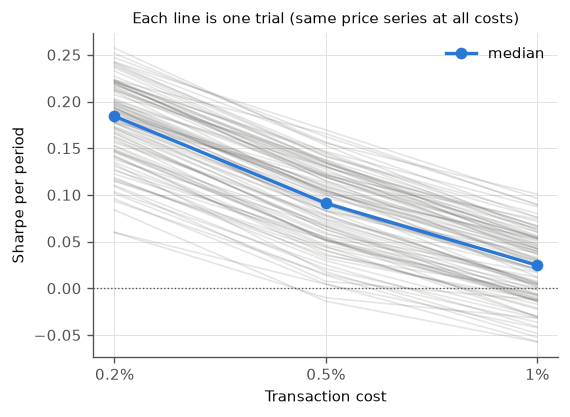

trials with Sharpe <= 0 at 1% cost: 30


In [7]:
# Paired view: how each trial's Sharpe changes as the cost goes up.
wide = trials.pivot(index="seed", columns="cost", values="sharpe")[["0.2%", "0.5%", "1%"]]
fig, ax = plt.subplots(figsize=(5, 3.5))
for _, row in wide.iterrows():
    ax.plot(range(3), row.values, color=INK_2, alpha=0.15, lw=1)
ax.plot(range(3), wide.median().values, "o-", color=SERIES[0], lw=2, label="median")
ax.axhline(0, color=INK_2, lw=0.8, ls=":")
ax.set_xticks(range(3), wide.columns); ax.set_xlabel("Transaction cost"); ax.set_ylabel("Sharpe per period")
ax.set_title("Each line is one trial (same price series at all costs)", fontsize=9); ax.legend()
plt.show()
print("trials with Sharpe <= 0 at 1% cost:", (wide["1%"] <= 0).sum())

## 3. Experiment 2: S&P 500 / T-bill allocation, RRL vs Q-learning (paper Sec. IV-C)

> **SUBSTITUTE DATA.** The paper used 84 Citibase series we do not have. These results use 16 inputs built from public data (Yahoo month-end S&P 500 closes, Shiller, FRED). **They are not a replication on the paper's data.**

Test period 1970–1994, cost 0.5%, yearly retraining, 30 RRL traders and 10 Q-traders combined by majority vote. Sharpe is annualized, on returns in excess of the T-bill rate.

In [8]:
s2 = json.loads((RES / "exp2_summary.json").read_text())
rows = []
for name in ["Buy and hold", "RRL committee", "Q committee"]:
    s, p = s2[name], s2["paper"][name]
    rows.append({"strategy": name, "final equity (ours)": s["final_equity"], "(paper)": p["final_equity"],
                 "excess Sharpe (ours)": s["sharpe"], "(paper) ": p["sharpe"],
                 "max drawdown": s["max_drawdown"], "trades % of months": s["trade_freq_pct"]})
print("config:", s2["config"])
pd.DataFrame(rows).set_index("strategy")

config: {'seed': 0, 'n_rrl': 30, 'n_q': 10, 'rho': 0.03, 'q': {'fit_epochs': 30, 'weight_decay': 0.01}, 'eta': 0.01, 'weight_decay': 0.01, 'delta': 0.005, 'data': 'SUBSTITUTE data: Yahoo ^GSPC, Shiller, FRED'}


,final equity (ours),(paper),excess Sharpe (ours),(paper),max drawdown,trades % of months
strategy,,,,,,
Buy and hold,13.154,13.48,0.293,0.34,0.427,0.000
RRL committee,39.974,58.60,0.592,0.83,0.212,13.000
Q committee,15.657,33.59,0.343,0.63,0.293,20.667


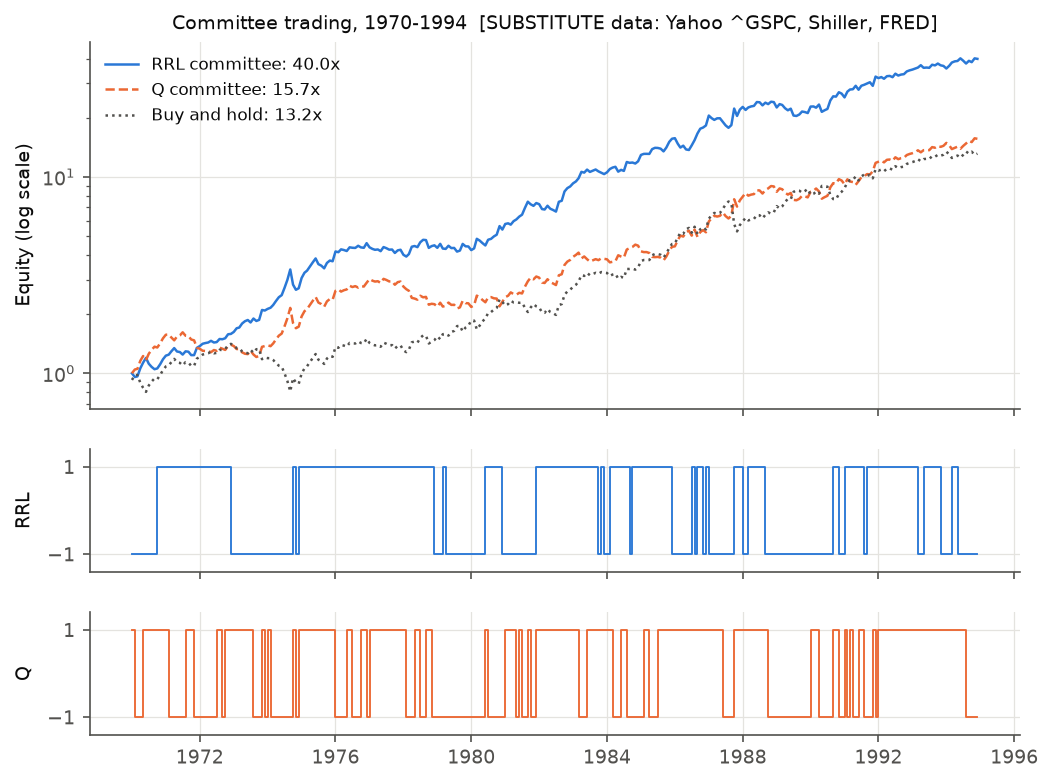

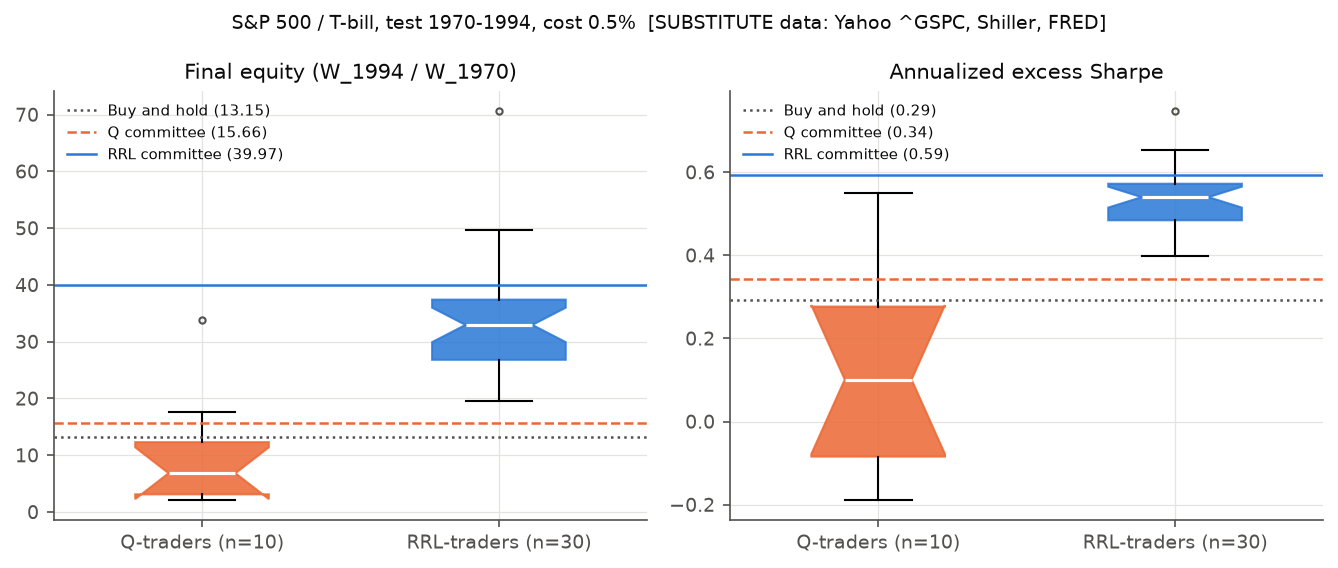

In [9]:
display(Image(RES / "exp2_fig9_equity.png"))
display(Image(RES / "exp2_fig8_boxplots.png"))

### Individual traders

In [10]:
traders = pd.read_csv(RES / "exp2_traders.csv")
bh = s2["Buy and hold"]["final_equity"]
print(traders.groupby("method").apply(lambda g: f"{(g.final_equity > bh).sum()} of {len(g)} beat buy-and-hold ({bh:.2f}x)",
                                      include_groups=False).to_string())
traders.groupby("method")[["final_equity", "sharpe", "max_drawdown", "trade_freq_pct"]].describe().T

method
Q       3 of 10 beat buy-and-hold (13.15x)
RRL    30 of 30 beat buy-and-hold (13.15x)


method                     Q     RRL
final_equity   count  10.000  30.000
               mean    9.900  33.948
               std     9.856  10.478
               min     2.071  19.567
               25%     3.102  26.809
               50%     6.823  32.950
               75%    12.289  37.400
               max    33.745  70.678
sharpe         count  10.000  30.000
               mean    0.119   0.537
               std     0.245   0.077
               min    -0.189   0.399
               25%    -0.084   0.484
               50%     0.101   0.540
               75%     0.276   0.572
               max     0.551   0.748
max_drawdown   count  10.000  30.000
               mean    0.344   0.212
               std     0.109   0.047
               min     0.222   0.154
               25%     0.272   0.200
               50%     0.295   0.212
               75%     0.398   0.215
               max     0.537   0.361
trade_freq_pct count  10.000  30.000
               mean   22.933  13.300
               std     3.399   2.467
               min    17.000   9.000
               25%    20.167  11.833
               50%    24.333  13.667
               75%    25.250  14.333
               max    27.333  19.667

In [11]:
traders.sort_values(["method", "final_equity"], ascending=[True, False])

,method,trader,seed,final_equity,sharpe,max_drawdown,trade_freq_pct
37,Q,7,7,33.745,0.551,0.296,17.000
35,Q,5,5,17.613,0.377,0.222,19.000
36,Q,6,6,13.206,0.299,0.265,24.667
34,Q,4,4,9.537,0.210,0.239,21.667
31,Q,1,1,9.503,0.209,0.292,25.000
30,Q,0,0,4.143,-0.007,0.403,27.333
39,Q,9,9,3.416,-0.057,0.383,19.667
38,Q,8,8,2.997,-0.093,0.294,24.000
33,Q,3,3,2.766,-0.111,0.504,25.333
32,Q,2,2,2.071,-0.189,0.537,25.667


### When is the committee long or short?

Much of the RRL edge comes from being short (and earning 2× the T-bill rate) during the high-rate 1970s and 80s.

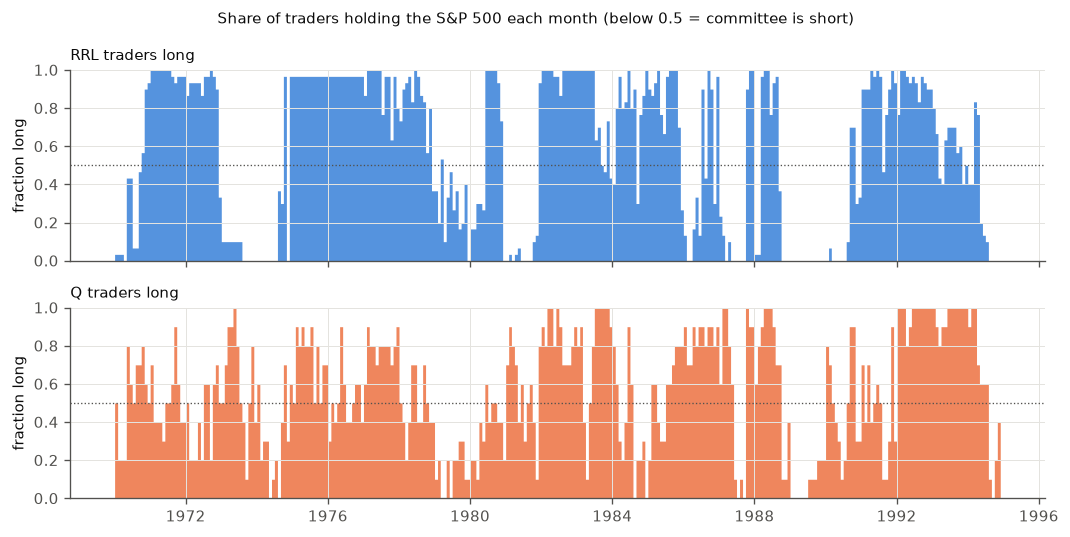

RRL committee short in 42% of all months
RRL committee short, by year (% of months):
1970     75
1971      0
1972      8
1973    100
1974     83
1975      0
1976      0
1977      0
1978      8
1979     92
1980     50
1981     92
1982      0
1983     17
1984     17
1985      8
1986     67
1987     75
1988     50
1989    100
1990     83
1991      8
1992      0
1993     33
1994     83


In [12]:
pos = np.load(RES / "exp2_positions.npz")
months = pd.PeriodIndex(pos["months"], freq="M").to_timestamp()
frac_long = pd.DataFrame({"RRL traders long": (pos["F_rrl"] > 0).mean(axis=0),
                          "Q traders long": (pos["F_q"] > 0).mean(axis=0)}, index=months)

fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for a, (col, c) in zip(ax, [("RRL traders long", SERIES[0]), ("Q traders long", SERIES[1])]):
    a.fill_between(frac_long.index, frac_long[col], step="post", color=c, alpha=0.8, lw=0)
    a.axhline(0.5, color=INK_2, lw=0.8, ls=":")
    a.set_ylim(0, 1); a.set_ylabel("fraction long"); a.set_title(col, fontsize=9, loc="left")
fig.suptitle("Share of traders holding the S&P 500 each month (below 0.5 = committee is short)", fontsize=9)
fig.tight_layout(); plt.show()

from experiments.exp2_sp500 import committee_vote   # majority vote; a tie keeps the previous position
committee_short = pd.Series(committee_vote(pos["F_rrl"]) < 0, index=months)
print(f"RRL committee short in {100 * committee_short.mean():.0f}% of all months")
print("RRL committee short, by year (% of months):")
print((100 * committee_short.groupby(committee_short.index.year).mean()).round(0).astype(int).to_string())

### Robustness: the whole experiment re-run with different base seeds

In [13]:
rows = []
for label, d in [("0 (reported)", RES), ("100", RES / "exp2_seed100"), ("200", RES / "exp2_seed200")]:
    s = json.loads((d / "exp2_summary.json").read_text())
    rows.append({"base seed": label, **{f"{k} final equity": s[k]["final_equity"]
                                       for k in ["RRL committee", "Q committee", "Buy and hold"]}})
pd.DataFrame(rows).set_index("base seed")

,RRL committee final equity,Q committee final equity,Buy and hold final equity
base seed,,,
0 (reported),39.974,15.657,13.154
100,33.561,12.891,13.154
200,41.500,8.324,13.154


## 4. Summary

- **Exp. 1:** RRL learns profitable strategies, and trade frequency, profit and Sharpe fall as costs rise, as in the paper. Trade frequencies match closely; our Sharpe ratios are lower, and the gap grows with cost.
- **Exp. 2 (substitute data):** the RRL committee beats buy-and-hold and the Q committee in every seed. The paper's Q-trader also beats buy-and-hold; ours is roughly level or worse, and fragile across seeds. We use plain Q-learning, not the paper's Advantage Updating.

See `README.md` ("Differences from the paper") and `NOTES.md` for details.